In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

In [2]:
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
    dest = os.path.join('images', filename)
    os.rename(filename, dest)
    print(f"File '{filename}' Moved To '{dest}'.")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Saving statue.png to statue.png
File 'statue.png' Moved To 'images/statue.png'.

Contents Of Images Folder:
['statue.png']


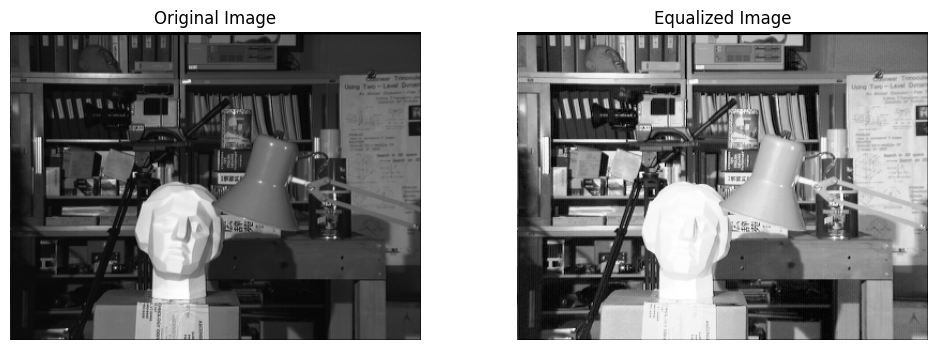

In [3]:
image = cv2.imread('images/statue.png', 0)
result = cv2.equalizeHist(image)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result, cmap='gray')
plt.title('Equalized Image')
plt.axis('off')

plt.show()

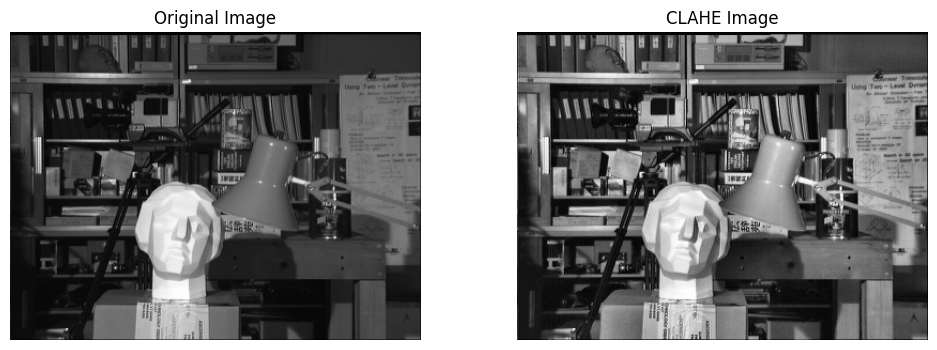

In [4]:
image = cv2.imread('images/statue.png', 0)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
result = clahe.apply(image)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result, cmap='gray')
plt.title('CLAHE Image')
plt.axis('off')

plt.show()

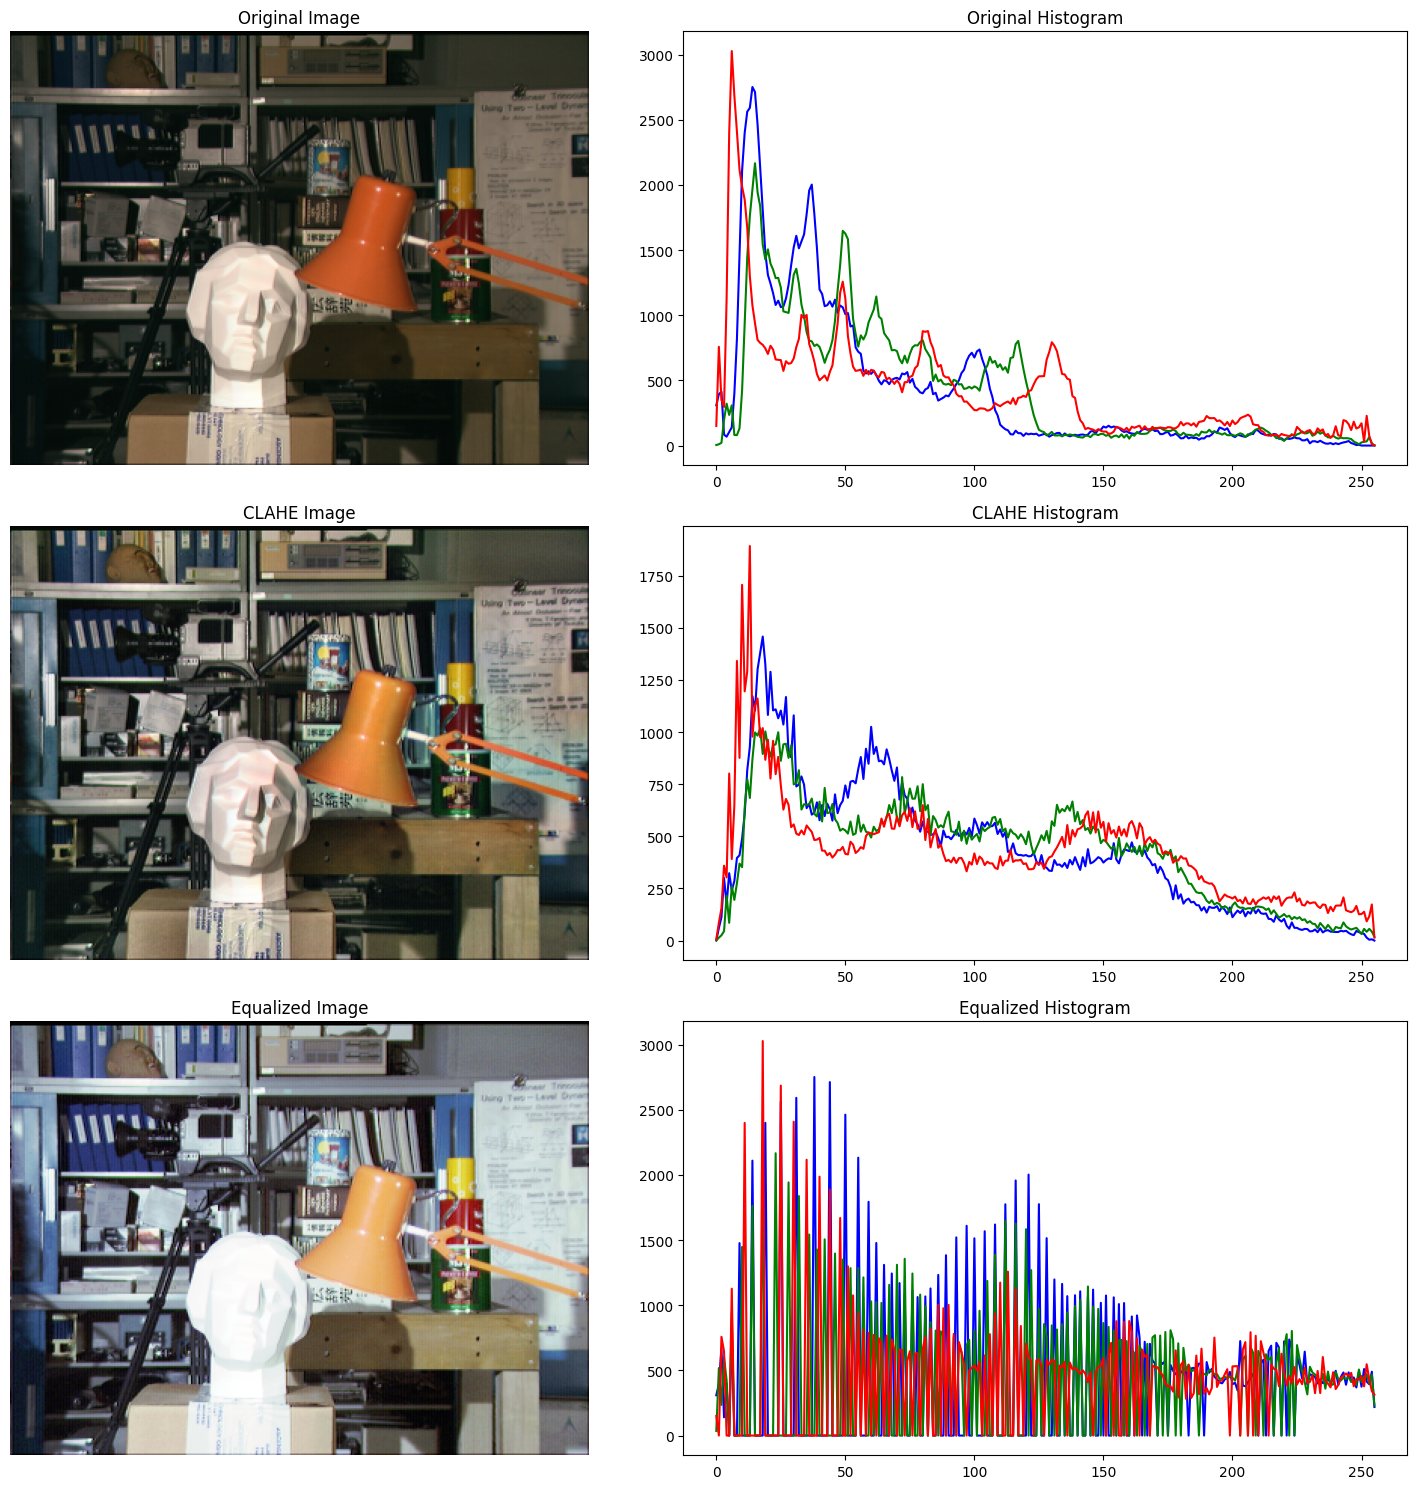

In [7]:
image = cv2.imread('images/statue.png')

channels = cv2.split(image)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_channels = []

for channel in channels:
    clahe_channels.append(clahe.apply(channel))
clahe_result = cv2.merge(clahe_channels)

eq_channels = []
for channel in channels:
    eq_channels.append(cv2.equalizeHist(channel))
eq_result = cv2.merge(eq_channels)

plt.figure(figsize=(15, 15))

plt.subplot(3, 2, 1)
plt.imshow(image[..., ::-1])
plt.title('Original Image')
plt.axis('off')

plt.subplot(3, 2, 3)
plt.imshow(clahe_result[..., ::-1])
plt.title('CLAHE Image')
plt.axis('off')

plt.subplot(3, 2, 5)
plt.imshow(eq_result[..., ::-1])
plt.title('Equalized Image')
plt.axis('off')

color = ('b', 'g', 'r')

for i, col in enumerate(color):
    histr = cv2.calcHist([channels[i]], [0], None, [256], [0, 256])
    plt.subplot(3, 2, 2)
    plt.plot(histr, color=col)
    plt.title('Original Histogram')

for i, col in enumerate(color):
    histr = cv2.calcHist([clahe_channels[i]], [0], None, [256], [0, 256])
    plt.subplot(3, 2, 4)
    plt.plot(histr, color=col)
    plt.title('CLAHE Histogram')

for i, col in enumerate(color):
    histr = cv2.calcHist([eq_channels[i]], [0], None, [256], [0, 256])
    plt.subplot(3, 2, 6)
    plt.plot(histr, color=col)
    plt.title('Equalized Histogram')

plt.tight_layout()
plt.show()